# Do discovery methods find different planets, or just look in different places?

**Question.** Do differences across discovery methods persist when we compare planets discovered in similar years, at similar distances, and around similar stars?

| Role | Variable |
|---|---|
| Outcome | Orbital period (log₁₀ days). Radius was considered first; see Section 1 for why we switched |
| Main predictor | Discovery method |
| Adjustment variables | Discovery year, distance from Earth (log₁₀ pc), host-star mass (M☉) |

**Plan.** (1) check which comparisons the data can support, (2) compare raw distributions, (3) check covariate overlap, (4) compare within similar groups (stratification), (5) multiple regression before and after adjustment, plus robustness checks.

**What this can and can't show.** This describes the *discovered population*. It can't measure a method's true detection efficiency, because the archive doesn't record the stars that were searched without finding a planet.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import statsmodels.formula.api as smf
from pathlib import Path

FIG = Path("figures/method_analysis"); FIG.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(237)

# Reference categorical palette, fixed order: color follows the method everywhere
COL = {"Transit": "#2a78d6", "Radial Velocity": "#eb6834",
       "Microlensing": "#1baf7a", "Imaging": "#eda100"}
INK, INK2, MUTED, GRID = "#1f1f1e", "#52514e", "#8a8984", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})

def log_days_axis(ax, axis="x"):
    fmt = mticker.FuncFormatter(lambda v, _: f"{10.0**v:,.0f}" if v >= 0 else f"{10.0**v:g}")
    (ax.xaxis if axis == "x" else ax.yaxis).set_major_formatter(fmt)

raw = pd.read_csv("data/PS_2026.10.11_20.14.11.csv", comment="#", low_memory=False)
df = raw[(raw.default_flag == 1) & (raw.pl_controv_flag == 0)].copy()
METHODS = ["Transit", "Radial Velocity", "Microlensing", "Imaging"]
df = df[df.discoverymethod.isin(METHODS)]
df["method"] = df.discoverymethod
print(f"{len(df):,} non-controversial planets from the four main methods")

6,329 non-controversial planets from the four main methods


## 1. Which comparisons can the data support?

Before comparing methods, check how often each method's planets have each variable at all.

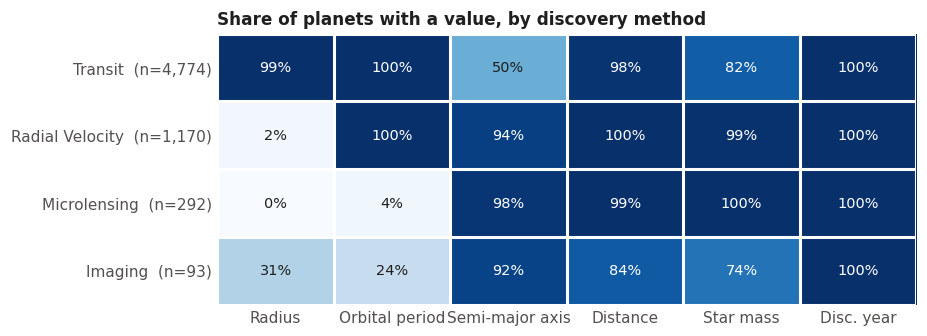

In [2]:
VARS = {"pl_rade": "Radius", "pl_orbper": "Orbital period", "pl_orbsmax": "Semi-major axis",
        "sy_dist": "Distance", "st_mass": "Star mass", "disc_year": "Disc. year"}
cov = df.groupby("method")[list(VARS)].apply(lambda g: g.notna().mean() * 100).loc[METHODS]
n = df.method.value_counts().loc[METHODS]

fig, ax = plt.subplots(figsize=(8.2, 3.2))
im = ax.imshow(cov.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(VARS)), VARS.values()); ax.set_yticks(range(4), [f"{m}  (n={n[m]:,})" for m in METHODS])
ax.tick_params(length=0); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
for i in range(cov.shape[0]):
    for j in range(cov.shape[1]):
        v = cov.values[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=9.5,
                color="white" if v > 55 else INK)
ax.set_xticks(np.arange(-.5, len(VARS)), minor=True); ax.set_yticks(np.arange(-.5, 4), minor=True)
ax.grid(which="minor", color="white", linewidth=2); ax.tick_params(which="minor", length=0)
ax.set_title("Share of planets with a value, by discovery method")
fig.savefig(FIG / "1_coverage.png"); plt.show()

In [3]:
complete = lambda col: df.dropna(subset=[col, "sy_dist", "st_mass"]).method.value_counts().reindex(METHODS, fill_value=0)
pd.DataFrame({"radius + covariates": complete("pl_rade"), "period + covariates": complete("pl_orbper")})

,radius + covariates,period + covariates
method,,
Transit,3827,3852
Radial Velocity,28,1153
Microlensing,0,11
Imaging,16,16


**Verdict on radius.** Radius is effectively a *transit-only* measurement: a planet only gets a radius if it is seen crossing its star. The 29 radial-velocity planets with radii are mostly ones that *later* turned out to transit (e.g., 55 Cnc e, GJ 436 b), and imaging radii come from brightness models, not direct measurement. A radius comparison across methods would mostly measure *which planets got a radius at all*, so we switch to the alternative outcome.

**Verdict on period.** Transit and radial velocity both have periods for nearly every planet (n ≈ 3,900 and 1,200 with all covariates). Microlensing and imaging rarely do (11 and 16 complete cases), because both detect planets on very long orbits that haven't been followed through a full cycle. **The core analysis is therefore Transit vs. Radial Velocity.** Microlensing and imaging still appear in the overlap check (Section 3) to show *why* they can't be compared fairly.

## 2. Stage 1: raw comparison

In [4]:
tv = df[df.method.isin(["Transit", "Radial Velocity"])].dropna(subset=["pl_orbper"])
tv = tv[tv.pl_orbperlim.fillna(0) == 0].copy()          # drop period upper/lower limits
tv["logP"] = np.log10(tv.pl_orbper)
tv["rv"] = (tv.method == "Radial Velocity").astype(int)

def boot_median_ratio(a, b, B=2000):
    a, b = np.asarray(a), np.asarray(b)
    r = [np.median(rng.choice(b, b.size)) / np.median(rng.choice(a, a.size)) for _ in range(B)]
    return np.median(b) / np.median(a), *np.percentile(r, [2.5, 97.5])

summ = tv.groupby("method").pl_orbper.describe(percentiles=[.1, .25, .5, .75, .9])
print(summ[["count", "10%", "25%", "50%", "75%", "90%"]].round(1).to_string())
ratio_raw = boot_median_ratio(tv.loc[tv.rv == 0, "pl_orbper"], tv.loc[tv.rv == 1, "pl_orbper"])
print("\nMedian RV period / median transit period = {:.1f}x  (95% bootstrap CI {:.1f}-{:.1f})".format(*ratio_raw))

                  count  10%   25%    50%     75%     90%
method                                                   
Radial Velocity  1163.0  5.8  21.3  302.8  1144.3  3988.6
Transit          4759.0  2.2   3.8    8.0    18.8    46.8



Median RV period / median transit period = 37.9x  (95% bootstrap CI 30.2-47.3)


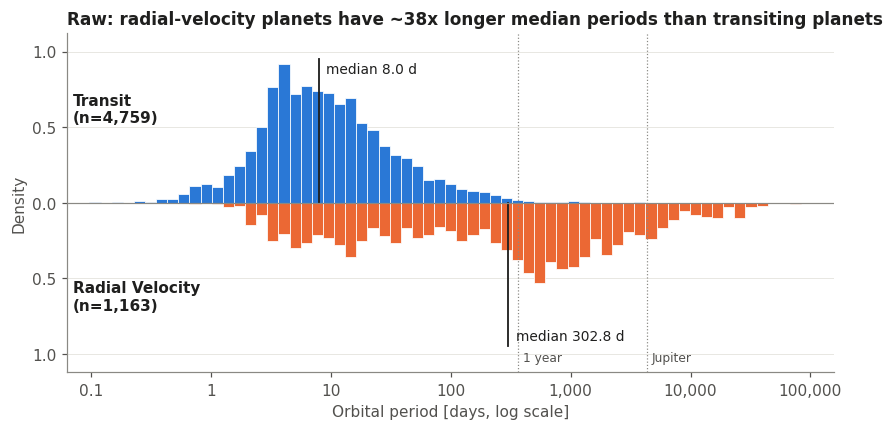

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.linspace(-1.2, 5.2, 70)
for m, sign in [("Transit", 1), ("Radial Velocity", -1)]:
    x = tv.loc[tv.method == m, "logP"]
    h, e = np.histogram(x, bins=bins, density=True)
    ax.bar(e[:-1], sign * h, width=np.diff(e), align="edge", color=COL[m], edgecolor="white", linewidth=0.5)
    med = x.median()
    ax.plot([med, med], [0, sign * 0.95], color=INK, lw=1.2)
    ax.text(med + 0.06, sign * 0.88, f"median {10**med:,.1f} d", va="center", fontsize=9, color=INK)
    ax.text(-1.15, sign * 0.62, f"{m}\n(n={len(x):,})", fontsize=10, fontweight="bold", color=INK, va="center")
ax.axhline(0, color=MUTED, lw=0.8)
for p, lab in [(365.25, "1 year"), (4332.6, "Jupiter")]:
    ax.axvline(np.log10(p), color=MUTED, lw=0.8, ls=":")
    ax.text(np.log10(p) + 0.04, -1.05, lab, fontsize=8, color=INK2)
ax.set_ylim(-1.12, 1.12); ax.set_xlim(-1.2, 5.2); ax.set_yticks([-1, -0.5, 0, 0.5, 1])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{abs(v):.1f}"))
log_days_axis(ax); ax.set_xticks(range(-1, 6))
ax.set_xlabel("Orbital period [days, log scale]"); ax.set_ylabel("Density")
ax.grid(axis="x", visible=False)
ax.set_title(f"Raw: radial-velocity planets have ~{ratio_raw[0]:.0f}x longer median periods than transiting planets")
fig.savefig(FIG / "2_raw_period.png"); plt.show()

The difference is large: half of transiting planets orbit in under ~10 days, while the median radial-velocity planet takes most of a year. This is consistent with geometry (transit probability falls roughly as 1/a) and with survey baselines (Kepler's ~4 years, TESS's ~27-day sectors). The RV distribution is also much wider and has two peaks (a hot-planet bump near 4-20 days plus a large peak near 1-3 years), so a single number summarizes it poorly. That's why the regression in Section 5, which compares *geometric means* (averages on the log scale), gives a smaller raw ratio (~22x) than this ratio of medians. But the two methods also look at **different stars in different places**, which is what the rest of the notebook checks.

## 3. Do the methods observe comparable stars? (overlap check)

A fair adjusted comparison needs both methods to have planets across the same range of each covariate. If they don't overlap, a regression just extrapolates.

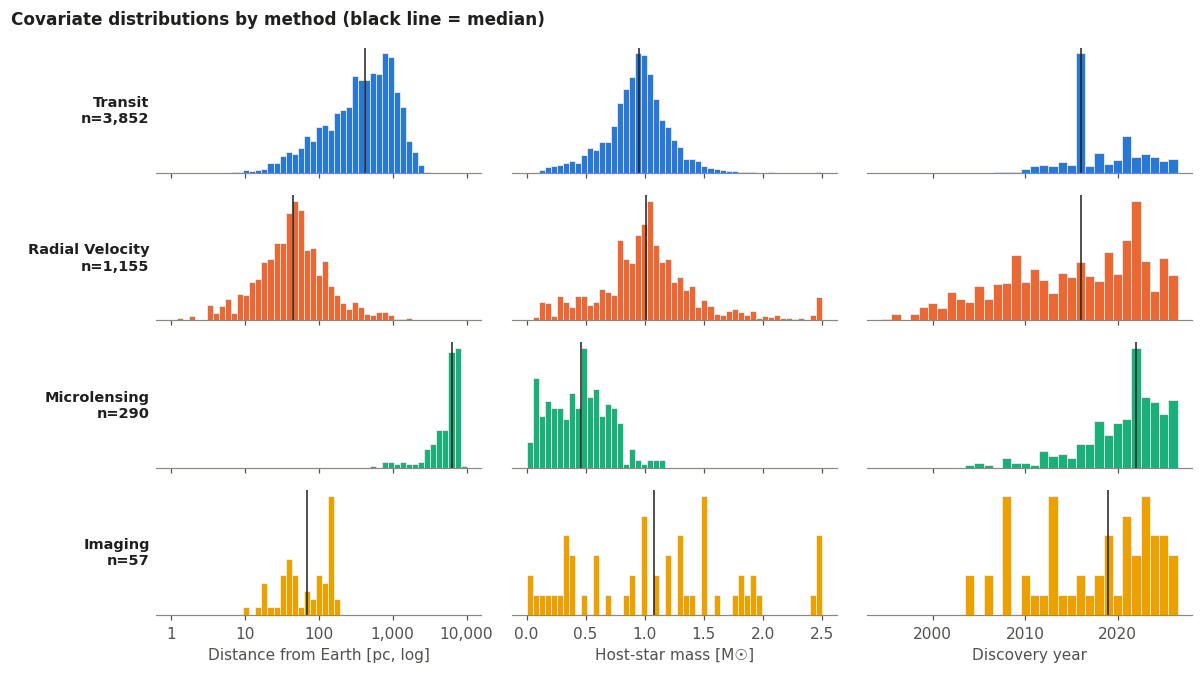

In [6]:
cv = df.dropna(subset=["sy_dist", "st_mass"]).copy()
cv["logd"] = np.log10(cv.sy_dist)
panels = [("logd", "Distance from Earth [pc, log]", np.linspace(0, 4, 50)),
          ("st_mass", "Host-star mass [M☉]", np.linspace(0, 2.5, 50)),
          ("disc_year", "Discovery year", np.arange(1994.5, 2027.5, 1))]

fig, axes = plt.subplots(4, 3, figsize=(11, 6.2), sharex="col")
for j, (var, lab, bins) in enumerate(panels):
    for i, m in enumerate(METHODS):
        ax = axes[i, j]
        x = cv.loc[cv.method == m, var]
        ax.hist(x.clip(bins[0], bins[-1]), bins=bins, color=COL[m], edgecolor="white", linewidth=0.4)
        ax.axvline(x.median(), color=INK, lw=1)
        ax.set_yticks([]); ax.spines["left"].set_visible(False); ax.grid(False)
        if j == 0:
            ax.text(-0.02, 0.5, f"{m}\nn={len(x):,}", transform=ax.transAxes, ha="right", va="center",
                    fontsize=9.5, fontweight="bold")
        if i == 3: ax.set_xlabel(lab)
axes[3, 0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{10.0**v:,.0f}"))
fig.suptitle("Covariate distributions by method (black line = median)", x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(); fig.subplots_adjust(left=0.13)
fig.savefig(FIG / "3_overlap.png"); plt.show()

In [7]:
print(cv.groupby("method")[["sy_dist", "st_mass", "disc_year"]].median().loc[METHODS].round(2).to_string())

                 sy_dist  st_mass  disc_year
method                                      
Transit           423.45     0.95     2016.0
Radial Velocity    45.09     1.01     2016.0
Microlensing     6270.00     0.46     2022.0
Imaging            69.57     1.08     2019.0


**Overlap findings:**
- **Microlensing** planets sit at ~6,000 pc, a range almost no RV planet reaches (RV median ≈ 44 pc), and they orbit lower-mass stars. There is no common ground for a fair comparison, which confirms excluding it.
- **Transit vs. RV:** distance is the biggest imbalance. Transiting planets have a median distance of ~460 pc versus ~44 pc for RV, a 10x difference, but the two distributions *do* overlap between roughly 20 and 600 pc. Star mass and discovery year overlap well.

So we define a **common-support sample**: Transit and RV planets with distance, star mass and discovery year inside the range covered by both methods (each method's 2.5th to 97.5th percentile).

In [8]:
a = tv.dropna(subset=["sy_dist", "st_mass"]).copy()
a["logd"] = np.log10(a.sy_dist)
a["year_c"] = a.disc_year - 2015
supp = {}
for v in ["logd", "st_mass", "disc_year"]:
    q = a.groupby("method")[v].quantile([.025, .975]).unstack()
    supp[v] = (q[0.025].max(), q[0.975].min())
    print(f"{v:9s} common range: {supp[v][0]:.2f} to {supp[v][1]:.2f}" + (f"  ({10**supp[v][0]:.0f}-{10**supp[v][1]:.0f} pc)" if v == "logd" else ""))
in_supp = np.logical_and.reduce([a[v].between(*supp[v]) for v in supp])
cs = a[in_supp].copy()
print(f"\nAnalysis sample: {len(a):,} planets; common support: {len(cs):,}")
print(pd.crosstab(in_supp, a.method, rownames=["in common support"]))

logd      common range: 1.48 to 2.70  (30-505 pc)
st_mass   common range: 0.33 to 1.49
disc_year common range: 2010.28 to 2026.00

Analysis sample: 5,000 planets; common support: 2,311
method             Radial Velocity  Transit
in common support                          
False                          720     1969
True                           428     1883


## 4. Stage 2: compare like with like (stratification)

Within each slice of one covariate, compare the median period of the two methods. If the gap were *only* because RV looks at nearby stars, it would shrink toward 1x inside narrow distance bins.

In [9]:
def strat(data, var, edges, labels):
    rows = []
    d = data.assign(bin=pd.cut(data[var], edges, labels=labels))
    for b, g in d.groupby("bin", observed=True):
        t, r = g.loc[g.rv == 0, "pl_orbper"], g.loc[g.rv == 1, "pl_orbper"]
        row = {"bin": b, "n_transit": len(t), "n_rv": len(r)}
        for nm, x in [("transit", t), ("rv", r)]:
            if len(x) >= 10:
                bs = [np.median(rng.choice(x.values, len(x))) for _ in range(1000)]
                row |= {f"{nm}_med": x.median(), f"{nm}_lo": np.percentile(bs, 2.5), f"{nm}_hi": np.percentile(bs, 97.5)}
        if len(t) >= 10 and len(r) >= 10:
            row["ratio"] = r.median() / t.median()
        rows.append(row)
    return pd.DataFrame(rows)

S = {
    "Distance from Earth": strat(a, "sy_dist", [0, 25, 50, 100, 200, 400, 800, 1e5],
                                 ["<25 pc", "25-50", "50-100", "100-200", "200-400", "400-800", ">800 pc"]),
    "Discovery year":      strat(a, "disc_year", [1990, 2005, 2010, 2014, 2017, 2020, 2023, 2027],
                                 ["≤2005", "2006-10", "2011-14", "2015-17", "2018-20", "2021-23", "2024-26"]),
    "Host-star mass":      strat(a, "st_mass", [0, 0.5, 0.75, 0.9, 1.05, 1.25, 10],
                                 ["<0.5 M☉", "0.5-0.75", "0.75-0.9", "0.9-1.05", "1.05-1.25", ">1.25 M☉"]),
}
for k, v in S.items():
    print(k); print(v[["bin", "n_transit", "n_rv", "transit_med", "rv_med", "ratio"]].round(1).to_string(index=False)); print()

Distance from Earth
    bin  n_transit  n_rv  transit_med  rv_med  ratio
 <25 pc         67   303          4.5    29.6    6.6
  25-50        177   337          6.0   271.7   45.5
 50-100        305   278          7.3   591.2   80.6
100-200        507   139          6.2   484.2   77.8
200-400        788    53          5.7   501.8   87.6
400-800        971    23          7.1   522.2   73.3
>800 pc       1037    15         11.7   406.2   34.8

Discovery year
    bin  n_transit  n_rv  transit_med  rv_med  ratio
  ≤2005          4   150          NaN   263.4    NaN
2006-10         93   187          3.6   452.8  127.4
2011-14        381   156          8.7   486.4   55.8
2015-17       1553   137          8.8   257.8   29.2
2018-20        489   146          6.7    54.4    8.2
2021-23        846   243          7.9   479.9   60.9
2024-26        486   129          5.5    58.9   10.7

Host-star mass
      bin  n_transit  n_rv  transit_med  rv_med  ratio
  <0.5 M☉        240   132          4.6    14

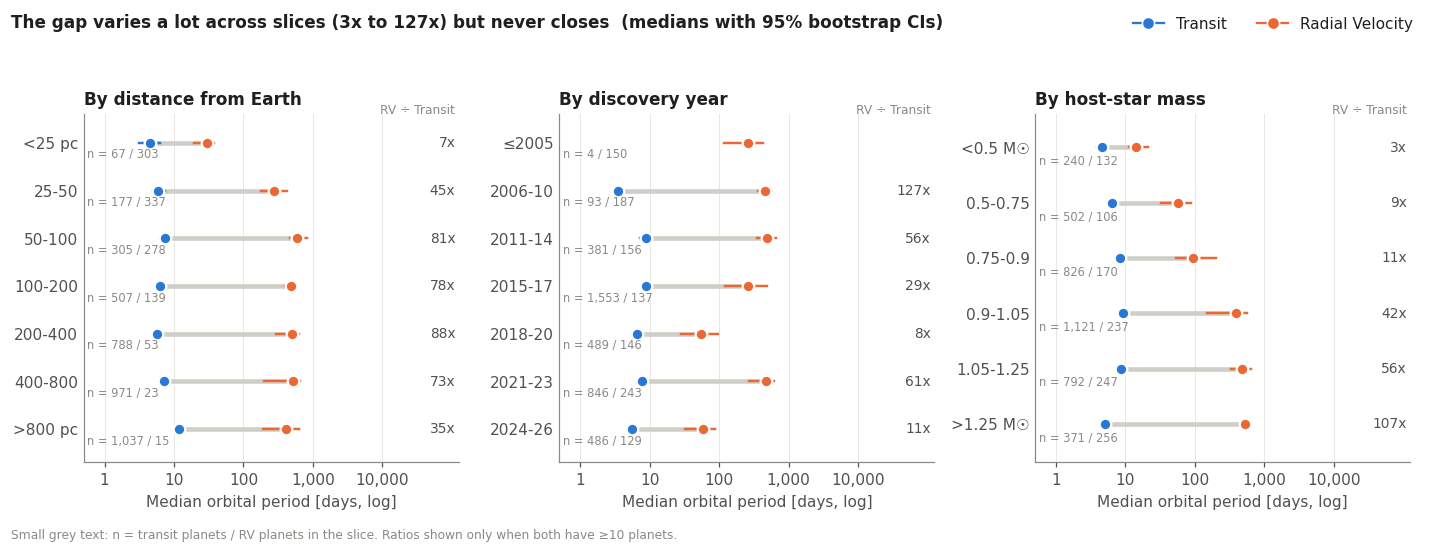

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8))
for ax, (title, s) in zip(axes, S.items()):
    y = np.arange(len(s))[::-1]
    for i, r in s.iterrows():
        yy = y[i]
        if pd.notna(r.get("ratio")):
            ax.plot([np.log10(r.transit_med), np.log10(r.rv_med)], [yy, yy], color="#cfcec8", lw=3, zorder=1, solid_capstyle="round")
            ax.text(5.05, yy, f"{r.ratio:.0f}x", va="center", ha="right", fontsize=9, color=INK2)
        for nm, m, off in [("transit", "Transit", 0.0), ("rv", "Radial Velocity", 0.0)]:
            if pd.notna(r.get(f"{nm}_med")):
                ax.plot([np.log10(r[f"{nm}_lo"]), np.log10(r[f"{nm}_hi"])], [yy, yy], color=COL[m], lw=1.6, zorder=2)
                ax.scatter(np.log10(r[f"{nm}_med"]), yy, s=58, color=COL[m], edgecolor="white", linewidth=1.5, zorder=3)
        ax.text(-0.25, yy - 0.32, f"n = {r.n_transit:,} / {r.n_rv:,}", fontsize=7.5, color=MUTED)
    ax.set_ylim(-0.7, len(s) - 0.4)
    ax.set_yticks(y, s.bin); ax.set_xlim(-0.3, 5.1); ax.set_xticks(range(0, 5)); log_days_axis(ax)
    ax.set_xlabel("Median orbital period [days, log]"); ax.set_title(f"By {title[0].lower() + title[1:]}")
    ax.grid(axis="y", visible=False); ax.tick_params(axis="y", length=0)
for ax in axes: ax.text(5.05, ax.get_ylim()[1] - 0.05, "RV ÷ Transit", ha="right", va="bottom", fontsize=8, color=MUTED)
fig.text(0.01, 0.005, "Small grey text: n = transit planets / RV planets in the slice. Ratios shown only when both have ≥10 planets.", fontsize=8, color=MUTED)
h = [plt.Line2D([], [], marker="o", ls="-", color=COL[m], markeredgecolor="white", markersize=8, label=m)
     for m in ["Transit", "Radial Velocity"]]
fig.legend(handles=h, loc="upper right", ncol=2, bbox_to_anchor=(1, 1.02))
fig.suptitle("The gap varies a lot across slices (3x to 127x) but never closes  (medians with 95% bootstrap CIs)",
             x=0.01, ha="left", fontweight="bold", fontsize=11, y=1.0)
fig.tight_layout(rect=(0, 0.03, 1, 0.95))
fig.savefig(FIG / "4_stratified.png"); plt.show()

**What the slices show:**
- **Distance:** the gap is *smallest* for the nearest stars (~7x within 25 pc) and ~75-90x between 50 and 800 pc. The transit medians barely move with distance (~5-12 days in every bin); it's the nearby RV planets that have shorter periods. But many of the nearest RV hosts are M dwarfs, so this may really be the star-mass pattern below (Section 5c checks this).
- **Star mass:** the clearest pattern. Around low-mass stars (< 0.5 M☉, M dwarfs) the gap is only ~3x; around stars above 1.25 M☉ it exceeds 100x. RV signals are stronger around light stars, and their close-in planets are easier to confirm, so RV around M dwarfs finds short-period planets similar to transit planets.
- **Year:** no steady trend. RV medians drop in 2018-20 and 2024-26, years when RV surveys of M dwarfs were productive.

Stratifying on one variable at a time can't adjust for all three together, which is what the regression does.

## 5. Stage 3: multiple regression

$$\log_{10}(\text{period}) = \beta_0 + \beta_1\,\text{RV} + \beta_2\,(\text{year}-2015) + \beta_3\,\log_{10}(\text{distance}) + \beta_4\,\text{star mass} + \varepsilon$$

$10^{\beta_1}$ is the multiplicative difference in period for an RV planet compared with a transiting planet, holding the other variables fixed. Standard errors are heteroskedasticity-robust (HC3). We fit a sequence of models adding one covariate at a time, then repeat on the common-support sample and with median (quantile) regression, which is less sensitive to the skewed period distribution.

In [11]:
specs = [
    ("Unadjusted",                  "logP ~ rv",                                   a,  "ols"),
    ("+ discovery year",            "logP ~ rv + year_c",                          a,  "ols"),
    ("+ distance",                  "logP ~ rv + year_c + logd",                   a,  "ols"),
    ("+ star mass (full model)",    "logP ~ rv + year_c + logd + st_mass",         a,  "ols"),
    ("Full model, common support",  "logP ~ rv + year_c + logd + st_mass",         cs, "ols"),
    ("Median regression, common support", "logP ~ rv + year_c + logd + st_mass",   cs, "qr"),
]
res, fits = [], {}
for name, f, data, kind in specs:
    m = smf.ols(f, data).fit(cov_type="HC3") if kind == "ols" else smf.quantreg(f, data).fit(q=0.5)
    fits[name] = m
    b, (lo, hi) = m.params["rv"], m.conf_int().loc["rv"]
    res.append({"model": name, "n": int(m.nobs), "beta_rv": b, "ratio": 10**b, "lo": 10**lo, "hi": 10**hi,
                "R2": getattr(m, "rsquared", np.nan)})
res = pd.DataFrame(res)
res.round(3)

,model,n,beta_rv,ratio,lo,hi,R2
0,Unadjusted,5000,1.345,22.128,19.100,25.636,0.391
1,+ discovery year,5000,1.331,21.411,18.318,25.025,0.392
2,+ distance,5000,1.666,46.367,39.114,54.963,0.423
3,+ star mass (full model),5000,1.575,37.616,31.224,45.317,0.429
4,"Full model, common support",2311,1.604,40.167,31.011,52.027,0.509
5,"Median regression, common support",2311,1.769,58.786,48.054,71.914,NaN


In [12]:
print(fits["+ star mass (full model)"].summary().tables[1])
print()
print(fits["Full model, common support"].summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0390      0.056      0.702      0.482      -0.070       0.148
rv             1.5754      0.041     38.175      0.000       1.494       1.656
year_c         0.0037      0.002      1.523      0.128      -0.001       0.008
logd           0.2670      0.023     11.382      0.000       0.221       0.313
st_mass        0.2172      0.037      5.858      0.000       0.145       0.290

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.8908      0.102      8.760      0.000       0.691       1.090
rv             1.6039      0.057     27.978      0.000       1.492       1.716
year_c        -0.0067      0.004     -1.901      0.057      -0.014       0.000
logd          -0.1097      0.046     -2.383      0.

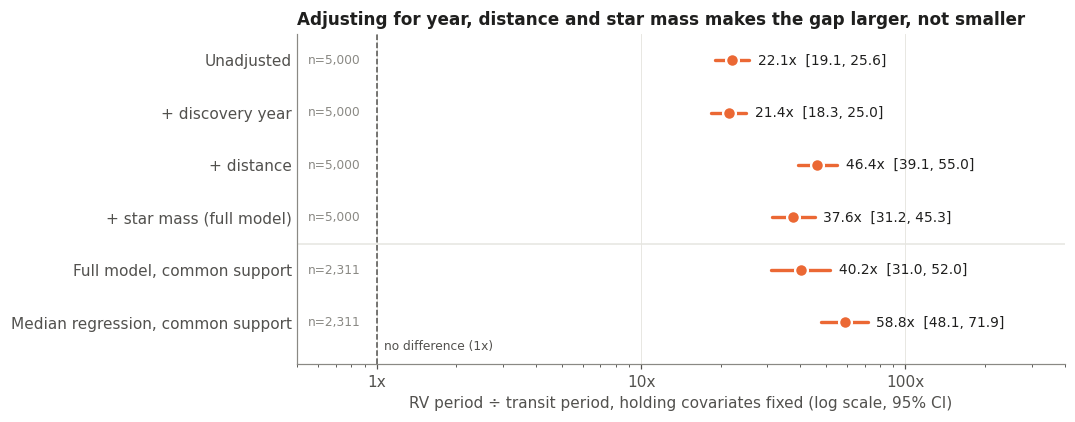

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.9))
y = np.arange(len(res))[::-1]
for yy, (_, r) in zip(y, res.iterrows()):
    c = COL["Radial Velocity"]
    ax.plot([r.lo, r.hi], [yy, yy], color=c, lw=2.2, solid_capstyle="round")
    ax.scatter(r.ratio, yy, s=70, color=c, edgecolor="white", linewidth=1.5, zorder=3)
    ax.text(r.hi * 1.08, yy, f"{r.ratio:.1f}x  [{r.lo:.1f}, {r.hi:.1f}]", va="center", fontsize=9, color=INK)
    ax.text(0.55, yy, f"n={r.n:,}", va="center", ha="left", fontsize=8, color=MUTED)
ax.axvline(1, color=INK2, lw=1, ls="--")
ax.text(1.06, y[-1] - 0.45, "no difference (1x)", fontsize=8, color=INK2, va="center")
ax.set_xscale("log"); ax.set_xlim(0.5, 400); ax.set_ylim(y[-1] - 0.8, y[0] + 0.5)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}x"))
ax.set_yticks(y, res.model); ax.tick_params(axis="y", length=0); ax.grid(axis="y", visible=False)
ax.axhline(y[3] - 0.5, color=GRID, lw=1)
ax.set_xlabel("RV period ÷ transit period, holding covariates fixed (log scale, 95% CI)")
ax.set_title("Adjusting for year, distance and star mass makes the gap larger, not smaller")
fig.savefig(FIG / "5_forest.png"); plt.show()

**Reading the forest plot.** The unadjusted model says the typical (geometric-mean) RV period is ~22x the transit period. Adding discovery year changes nothing. **Adding distance roughly doubles the gap to ~46x.** That happens because, within the pooled sample, farther planets tend to have longer periods (distant Kepler transits vs. nearby, shorter-period TESS transits and M-dwarf RV planets), and RV planets are mostly nearby. Comparing at the *same* distance therefore *removes* a factor that was making RV periods look closer to transit periods. Star mass pulls it back a little (~38x), because RV hosts are slightly heavier and heavier hosts have longer-period planets. Restricting to the common-support sample (~40x) and switching to median regression (~59x) leave the conclusion unchanged: **the difference is not explained by where or when the methods looked.** Distance was *hiding* part of the gap, not causing it.

### 5b. Has the gap changed over time?

Add a method × year interaction to the full model (common-support sample), then plot the predicted median period for each method by discovery year, holding distance and star mass at their sample medians.

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.8713      0.104      8.385      0.000       0.668       1.075
rv             1.6360      0.068     24.185      0.000       1.503       1.769
year_c        -0.0051      0.003     -1.544      0.123      -0.012       0.001
rv:year_c     -0.0065      0.011     -0.583      0.560      -0.029       0.015
logd          -0.1022      0.047     -2.173      0.030      -0.194      -0.010
st_mass        0.2876      0.057      5.028      0.000       0.176       0.400


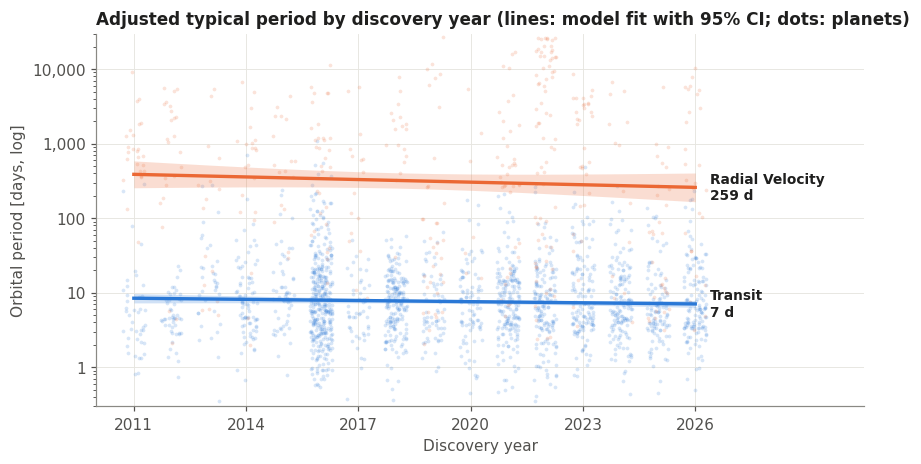

2011: RV/Transit = 45.9x
2026: RV/Transit = 36.6x


In [14]:
mi = smf.ols("logP ~ rv * year_c + logd + st_mass", cs).fit(cov_type="HC3")
print(mi.summary().tables[1])

years = np.arange(cs.disc_year.min(), cs.disc_year.max() + 1)
grid = pd.DataFrame([(yr, rv) for yr in years for rv in (0, 1)], columns=["disc_year", "rv"])
grid["year_c"] = grid.disc_year - 2015
grid["logd"] = cs.logd.median(); grid["st_mass"] = cs.st_mass.median()
pr = mi.get_prediction(grid).summary_frame(alpha=0.05)
grid[["fit", "lo", "hi"]] = 10 ** pr[["mean", "mean_ci_lower", "mean_ci_upper"]].values

fig, ax = plt.subplots(figsize=(9, 4.4))
for rv, m in [(0, "Transit"), (1, "Radial Velocity")]:
    g = grid[grid.rv == rv]; obs = cs[cs.rv == rv]
    ax.scatter(obs.disc_year + rng.uniform(-0.3, 0.3, len(obs)), obs.pl_orbper, s=6, color=COL[m], alpha=0.18, lw=0, zorder=1)
    ax.fill_between(g.disc_year, g.lo, g.hi, color=COL[m], alpha=0.22, lw=0, zorder=2)
    ax.plot(g.disc_year, g.fit, color=COL[m], lw=2.2, zorder=3)
    ax.text(g.disc_year.iloc[-1] + 0.4, g.fit.iloc[-1], f"{m}\n{g.fit.iloc[-1]:,.0f} d", va="center", fontsize=9, fontweight="bold")
ax.set_yscale("log"); ax.set_ylim(0.3, 3e4)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}" if v >= 1 else f"{v:g}"))
ax.set_xlim(years[0] - 1, years[-1] + 4.5); ax.set_xticks(range(2011, 2027, 3))
ax.set_xlabel("Discovery year"); ax.set_ylabel("Orbital period [days, log]")
ax.set_title("Adjusted typical period by discovery year (lines: model fit with 95% CI; dots: planets)")
fig.savefig(FIG / "5b_trend.png"); plt.show()

g0, g1 = grid[grid.disc_year == years[0]], grid[grid.disc_year == years[-1]]
for g in (g0, g1):
    print(f"{int(g.disc_year.iloc[0])}: RV/Transit = {g.fit.iloc[1] / g.fit.iloc[0]:.1f}x")

There's **no evidence the gap has changed over time** in the common-support sample: the method × year interaction is small and not significant (see the `rv:year_c` row above). Both lines drift down slightly, but the ~40x gap holds from 2011 to 2026.

### 5c. Where does the gap depend on the star? (interactions)

The stratified plots suggested the gap is smaller around low-mass and nearby stars. But in our data nearby RV hosts are often low-mass stars, so the two patterns could be the same thing. We separate them by letting the method effect vary with star mass *and* distance in one model:
`logP ~ rv * (st_mass + logd) + year_c`, fit on the common-support sample.

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.7985      0.098      8.121      0.000       0.606       0.991
rv             1.8449      0.384      4.802      0.000       1.092       2.598
st_mass        0.2267      0.054      4.214      0.000       0.121       0.332
logd          -0.0469      0.045     -1.047      0.295      -0.135       0.041
rv:st_mass     0.4046      0.244      1.659      0.097      -0.073       0.883
rv:logd       -0.3381      0.175     -1.927      0.054      -0.682       0.006
year_c        -0.0050      0.004     -1.381      0.167      -0.012       0.002


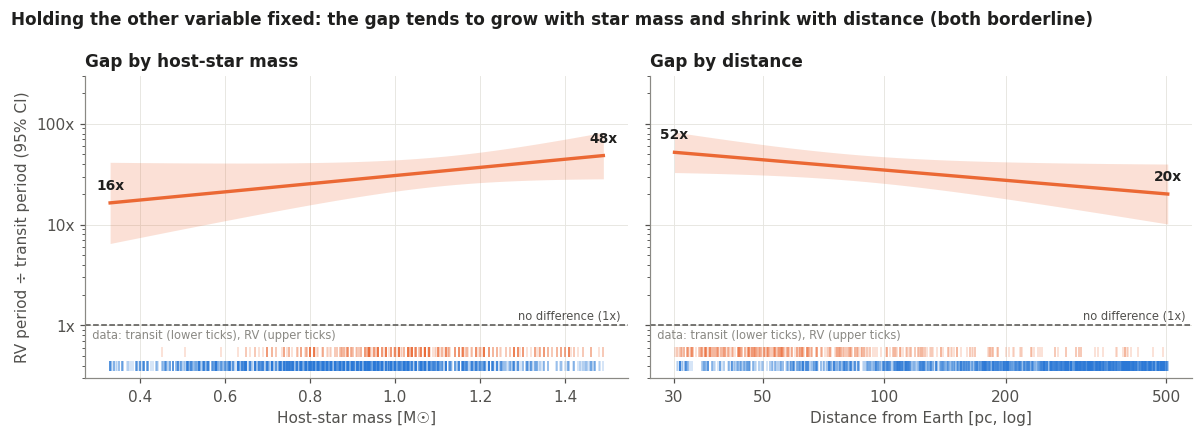

In [15]:
mh = smf.ols("logP ~ rv * (st_mass + logd) + year_c", cs).fit(cov_type="HC3")
print(mh.summary().tables[1])

def ratio_curve(var, xs):
    # method effect at each x, other interacting variable held at its median
    other = {"st_mass": ("logd", cs.logd.median()), "logd": ("st_mass", cs.st_mass.median())}[var]
    out = []
    V = mh.cov_params()
    for x in xs:
        L = pd.Series(0.0, index=mh.params.index)
        L["rv"] = 1; L[f"rv:{var}"] = x; L[f"rv:{other[0]}"] = other[1]
        b = L @ mh.params; se = np.sqrt(L @ V @ L)
        out.append((x, 10**b, 10**(b - 1.96 * se), 10**(b + 1.96 * se)))
    return pd.DataFrame(out, columns=["x", "ratio", "lo", "hi"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, var, lab, xs, fmt in [
    (axes[0], "st_mass", "Host-star mass [M☉]", np.linspace(*supp["st_mass"], 60), None),
    (axes[1], "logd", "Distance from Earth [pc, log]", np.linspace(*supp["logd"], 60), "dist"),
]:
    rc = ratio_curve(var, xs)
    ax.fill_between(rc.x, rc.lo, rc.hi, color=COL["Radial Velocity"], alpha=0.2, lw=0)
    ax.plot(rc.x, rc.ratio, color=COL["Radial Velocity"], lw=2.2)
    ax.axhline(1, color=INK2, lw=1, ls="--")
    ax.set_yscale("log"); ax.set_ylim(0.3, 300)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}x"))
    for i in (0, -1):
        ax.annotate(f"{rc.ratio.iloc[i]:.0f}x", (rc.x.iloc[i], rc.ratio.iloc[i]), xytext=(0, 9),
                    textcoords="offset points", ha="center", fontsize=9, fontweight="bold")
    # rug of where the data actually are
    for rv, m in [(0, "Transit"), (1, "Radial Velocity")]:
        v = cs.loc[cs.rv == rv, var]
        ax.plot(v, np.full(len(v), 0.4 if rv == 0 else 0.55), "|", color=COL[m], alpha=0.25, ms=6)
    ax.set_xlabel(lab)
    if fmt == "dist":
        ax.set_xticks(np.log10([30, 50, 100, 200, 500]))
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{10.0**v:,.0f}"))
axes[0].set_ylabel("RV period ÷ transit period (95% CI)")
axes[0].set_title("Gap by host-star mass"); axes[1].set_title("Gap by distance")
for ax in axes:
    ax.text(ax.get_xlim()[0], 0.7, "  data: transit (lower ticks), RV (upper ticks)", fontsize=7.5, color=MUTED, va="bottom")
    ax.text(ax.get_xlim()[1], 1.08, "no difference (1x)  ", fontsize=7.5, color=INK2, ha="right", va="bottom")
fig.suptitle("Holding the other variable fixed: the gap tends to grow with star mass and shrink with distance (both borderline)",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(); fig.savefig(FIG / "5c_heterogeneity.png"); plt.show()

**Result.** Holding distance fixed, the gap grows from ~16x around 0.35 M☉ stars to ~48x around 1.5 M☉ stars. This matches the stratified pattern, but the interaction is only borderline significant (p ≈ 0.10), so treat it as suggestive. **The distance pattern reverses** once star mass is held fixed: the gap is *larger* for nearby systems (~52x at 30 pc vs. ~20x at 500 pc, p ≈ 0.05). The small gap among the nearest stars in Section 4 therefore came from those stars being low-mass, not from distance itself. Few RV planets in common support orbit stars below ~0.6 M☉ (see the ticks), so the low-mass end of the curve is uncertain. The CIs are wide and neither interaction changes the main conclusion: the gap is well above 1x everywhere.

### 5d. Model diagnostics

Periods are bimodal within each method (hot planets on short orbits plus a long-period tail), so residuals aren't normal. That's why we use robust standard errors and check that the median regression agrees.

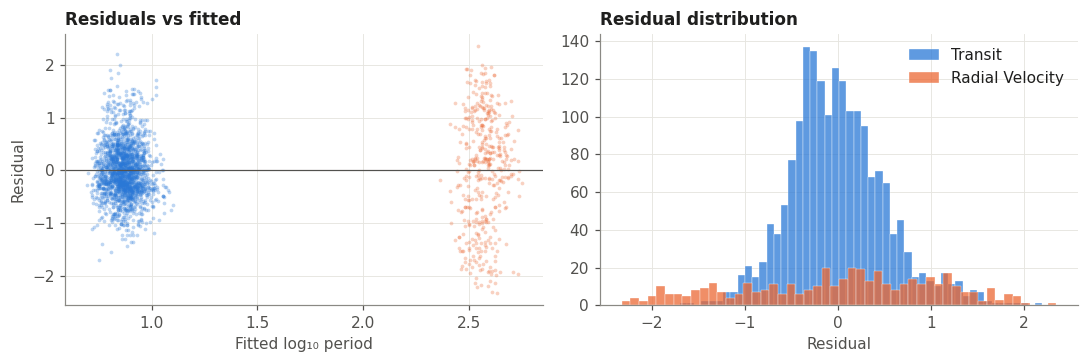

In [16]:
m = fits["Full model, common support"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for rv, mm in [(0, "Transit"), (1, "Radial Velocity")]:
    sel = cs.rv == rv
    axes[0].scatter(m.fittedvalues[sel], m.resid[sel], s=6, alpha=0.3, color=COL[mm], lw=0, label=mm)
    axes[1].hist(m.resid[sel], bins=50, color=COL[mm], alpha=0.75, edgecolor="white", linewidth=0.3, label=mm)
axes[0].axhline(0, color=INK2, lw=0.8); axes[0].set_xlabel("Fitted log₁₀ period"); axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs fitted"); axes[1].set_title("Residual distribution"); axes[1].set_xlabel("Residual")
axes[1].legend(); fig.tight_layout(); fig.savefig(FIG / "5d_diagnostics.png"); plt.show()

## 6. Conclusions

**Short answer: yes, the difference persists, and it gets larger after adjustment.** Radial-velocity planets have much longer orbital periods than transiting planets even when compared at similar discovery years, distances and host-star masses.

1. **Radius can't answer the question.** Only transit planets reliably have radii (99% vs. 2% for RV, 0% for microlensing), so a radius comparison would compare *how values were obtained*. Orbital period works, but only for Transit vs. Radial Velocity; microlensing and imaging rarely have periods, and microlensing doesn't overlap with RV in distance at all.
2. **Raw gap:** the median RV period is ~38x the median transit period (302.8 vs. 8.0 days); on the log scale (geometric means) it's ~22x.
3. **The methods do look in different places.** Transiting planets are ~10x farther away (median ~420 vs. ~45 pc). Only about 2,300 of 5,000 planets fall in the range covered by both methods.
4. **Adjustment doesn't explain the gap away; it reveals more of it.** Controlling for distance raises the gap to ~46x; the full model gives ~38x [31-45], the common-support sample ~40x [31-52], and median regression ~59x [48-72]. Distance was *masking* part of the difference.
5. **No change over time:** the gap is about the same for planets discovered in 2011 and 2026.
6. **The gap seems to depend on the host star.** In raw slices it's ~3x around M dwarfs (< 0.5 M☉) and > 100x around stars above 1.25 M☉. In the interaction model, holding distance fixed, it goes from ~16x to ~48x across the common-support mass range, but this is only borderline significant (p ≈ 0.10). A plausible mechanism: RV signals are strongest for close-in planets around light stars, so there the two methods find more overlapping populations. The apparent "smaller gap for nearby stars" turned out to be a star-mass effect: once mass is held fixed, nearby systems actually show a *larger* gap.

**Limitations.** This is the *discovered* population. We can't separate "RV is better at finding long-period planets" from "RV targets were chosen because they were likely to host them," and we can't estimate true detection efficiency without the stars that were searched and came up empty. The only covariates are those in the archive (no stellar activity, survey cadence, or instrument precision), so the remaining gap may partly reflect unmeasured survey design. Periods are bimodal, so model residuals aren't normal; the robust SEs and median regression address this, and all specifications agree on direction and rough size. Default parameter sets mix measurements from different papers.